# Stochastic and Batch Gradient Descent in Matrix Form

**Contents**
1. Stochastic gradient descent: a hidden layer of 2 neurons
2. Batch gradient descent: a single neuron
3. Batch gradient descent: one hidden neuron and one output neuron

**Conventions (Sections 2 and 3).** The data $X$ is an $n \times k$ matrix: $n$ examples (rows), $k$ features (columns). Labels $Y$ are $n \times 1$.
A layer with $h$ neurons has weights $W$ of shape $k \times h$ (one **column** per neuron) and biases $b$ of length $h$, so the forward pass is $Z = XW + b$ and the transposes appear on the way back.

Hidden neurons use ReLU, the output neuron uses a sigmoid. Stochastic gradient descent uses the **loss** $L$ of one example; batch gradient descent uses the **cost** $J$, the average loss over all $n$ examples. $\alpha$ is the learning rate.

Cells marked **Example** can simply be run. Cells marked **Exercise** contain `# TODO` gaps for you to complete.

## 0. Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def numerical_gradients(loss_fn, *params, h=1e-5):
    """Estimate the gradient of loss_fn with respect to each parameter, by nudging it up and down.
    Used by the check cells to test your backward passes - you don't need to read it."""
    grads = []
    for k in range(len(params)):
        grad = np.zeros_like(np.array(params[k], dtype=float))
        for i in np.ndindex(grad.shape):
            plus = [np.array(q, dtype=float) for q in params]
            minus = [np.array(q, dtype=float) for q in params]
            plus[k][i] += h
            minus[k][i] -= h
            grad[i] = (loss_fn(*plus) - loss_fn(*minus)) / (2 * h)
        grads.append(grad)
    return grads


def gradients_match(analytic, numeric):
    """Return True if every gradient you computed matches its numerical estimate."""
    return all(np.allclose(a, n, atol=1e-6) for a, n in zip(analytic, numeric))

In [3]:
def sigmoid(z):
    """Output activation: maps any real number to (0, 1)."""
    return 1 / (1 + np.exp(-z))


def relu(z):
    """Hidden activation: max(0, z)."""
    return np.maximum(0, z)


def relu_slope(z):
    """Derivative of ReLU: 1 where z > 0, otherwise 0."""
    return np.where(z > 0, 1.0, 0.0)


def bce(a, y):
    """Binary cross-entropy loss, one value per example."""
    a = np.clip(a, 1e-12, 1 - 1e-12)
    return -(y * np.log(a) + (1 - y) * np.log(1 - a))

### The data: $n = 100$ examples, $k = 2$ features

X: (100, 2)   Y: (100, 1)


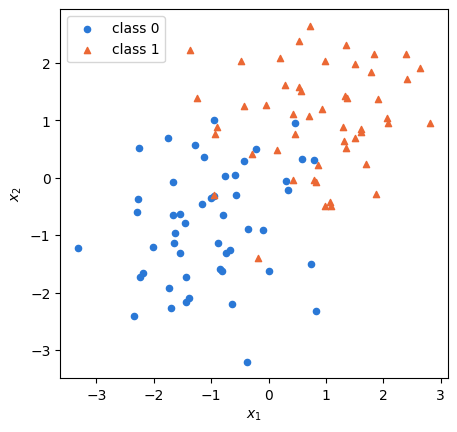

In [4]:
rng = np.random.default_rng(seed=0)
n, k = 100, 2

X = np.vstack([rng.normal([-1, -1], 1.0, (n // 2, k)),
               rng.normal([1, 1], 1.0, (n // 2, k))])
Y = np.vstack([np.zeros((n // 2, 1)), np.ones((n // 2, 1))])
shuffle = rng.permutation(n)
X, Y = X[shuffle], Y[shuffle]

print("X:", X.shape, "  Y:", Y.shape)

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(X[Y[:, 0] == 0, 0], X[Y[:, 0] == 0, 1], color="#2a78d6", s=20, label="class 0")
ax.scatter(X[Y[:, 0] == 1, 0], X[Y[:, 0] == 1, 1], color="#eb6834", s=20, marker="^", label="class 1")
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_aspect("equal")
ax.legend()
plt.show()

---
## 1. Stochastic Gradient Descent

The network: 2 inputs $\to$ 2 ReLU neurons $\to$ 1 sigmoid output neuron. Stochastic gradient descent updates the weights after **every single example**.
In this section everything is written neuron by neuron with ordinary numbers; Section 2 switches to matrix notation.

### Example 1: Forward and backward pass for one example

One example has features $x_1, x_2$ and label $y$. Weight $w^{[1]}_{ij}$ connects input $i$ to hidden neuron $j$.

**Forward:**

$$z^{[1]}_1 = w^{[1]}_{11}x_1 + w^{[1]}_{21}x_2 + b^{[1]}_1, \qquad a^{[1]}_1 = \text{ReLU}(z^{[1]}_1)$$
$$z^{[1]}_2 = w^{[1]}_{12}x_1 + w^{[1]}_{22}x_2 + b^{[1]}_2, \qquad a^{[1]}_2 = \text{ReLU}(z^{[1]}_2)$$
$$z^{[2]} = w^{[2]}_1 a^{[1]}_1 + w^{[2]}_2 a^{[1]}_2 + b^{[2]}, \qquad a^{[2]} = \sigma(z^{[2]})$$
$$L = -\big[y\log a^{[2]} + (1-y)\log(1-a^{[2]})\big]$$

**Backward:**

| Gradient | Formula |
|:--|:--|
| $\partial L/\partial z^{[2]}$ | $a^{[2]} - y$ |
| $\partial L/\partial w^{[2]}_j$, $\ \partial L/\partial b^{[2]}$ | $\dfrac{\partial L}{\partial z^{[2]}}\,a^{[1]}_j$, $\ \dfrac{\partial L}{\partial z^{[2]}}$ |
| $\partial L/\partial z^{[1]}_j$ | $\dfrac{\partial L}{\partial z^{[2]}}\,w^{[2]}_j\,\text{ReLU}'(z^{[1]}_j)$ |
| $\partial L/\partial w^{[1]}_{ij}$, $\ \partial L/\partial b^{[1]}_j$ | $\dfrac{\partial L}{\partial z^{[1]}_j}\,x_i$, $\ \dfrac{\partial L}{\partial z^{[1]}_j}$ |

In [5]:
def forward_sgd(x1, x2, w1_11, w1_21, b1_1, w1_12, w1_22, b1_2, w2_1, w2_2, b2):
    """Forward pass for one example. Returns every intermediate value."""
    z1_1 = w1_11 * x1 + w1_21 * x2 + b1_1
    a1_1 = relu(z1_1)
    z1_2 = w1_12 * x1 + w1_22 * x2 + b1_2
    a1_2 = relu(z1_2)
    z2 = w2_1 * a1_1 + w2_2 * a1_2 + b2
    a2 = sigmoid(z2)
    return z1_1, a1_1, z1_2, a1_2, z2, a2


def backward_sgd(x1, x2, y, w2_1, w2_2, z1_1, a1_1, z1_2, a1_2, a2):
    """Backward pass for one example. Returns the gradient of L for each of the 9 parameters."""
    dz2 = a2 - y
    dw2_1 = dz2 * a1_1
    dw2_2 = dz2 * a1_2
    db2 = dz2

    dz1_1 = dz2 * w2_1 * relu_slope(z1_1)
    dw1_11 = dz1_1 * x1
    dw1_21 = dz1_1 * x2
    db1_1 = dz1_1

    dz1_2 = dz2 * w2_2 * relu_slope(z1_2)
    dw1_12 = dz1_2 * x1
    dw1_22 = dz1_2 * x2
    db1_2 = dz1_2

    return dw1_11, dw1_21, db1_1, dw1_12, dw1_22, db1_2, dw2_1, dw2_2, db2

In [6]:
# Starting values
w1_11, w1_21, b1_1 = 0.17, 0.41, 0.1      # hidden neuron 1
w1_12, w1_22, b1_2 = 0.17, -0.65, 0.1     # hidden neuron 2
w2_1, w2_2, b2 = 0.45, 0.22, 0.0          # output neuron
start = (w1_11, w1_21, b1_1, w1_12, w1_22, b1_2, w2_1, w2_2, b2)

# The first example
x1, x2, y = X[0, 0], X[0, 1], Y[0, 0]

z1_1, a1_1, z1_2, a1_2, z2, a2 = forward_sgd(x1, x2, *start)
print(f"a1_1 = {a1_1:.4f}, a1_2 = {a1_2:.4f}, a2 = {a2:.4f}, L = {bce(a2, y):.4f}")

grads = backward_sgd(x1, x2, y, w2_1, w2_2, z1_1, a1_1, z1_2, a1_2, a2)
print("gradients:", np.round(grads, 4))

loss_sgd = lambda *p: bce(forward_sgd(x1, x2, *p)[5], y)
print(gradients_match(grads, numerical_gradients(loss_sgd, *start)))

a1_1 = 0.1300, a1_2 = 0.1861, a2 = 0.5248, L = 0.7441
gradients: [ 0.0718 -0.0125  0.2362  0.0351 -0.0061  0.1155  0.0682  0.0977  0.5248]
True


### Exercise 1: Training with stochastic gradient descent

Train for 10 epochs with $\alpha = 0.1$. An **epoch** is one pass through all $n$ examples, so it takes $n$ iterations.
Shuffle the order of the examples at the start of each epoch, and update all nine parameters after every example.

Plot the loss $L$ at every iteration, and mark the end of each epoch with a vertical line. Why is the curve so jagged?

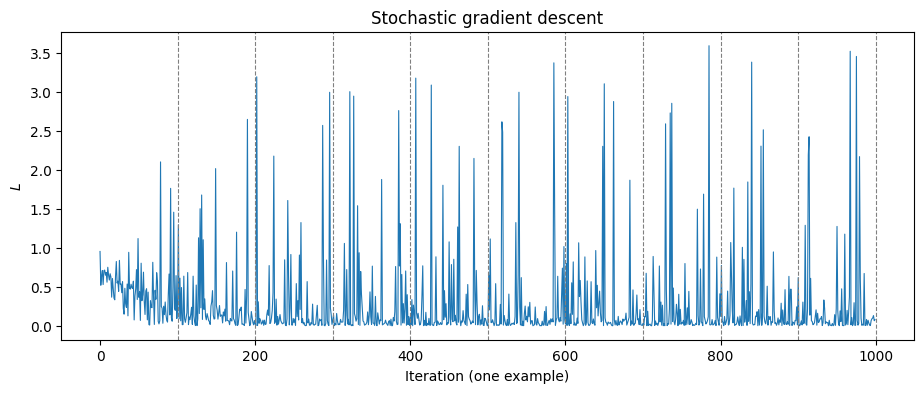

In [7]:
alpha = 0.1
n_epochs = 10
order_rng = np.random.default_rng(seed=2)

w1_11, w1_21, b1_1, w1_12, w1_22, b1_2, w2_1, w2_2, b2 = start
losses = []

for epoch in range(n_epochs):
    for i in order_rng.permutation(n):
        x1, x2, y = X[i, 0], X[i, 1], Y[i, 0]
        # forward pass
        z1_1, a1_1, z1_2, a1_2, z2, a2 = forward_sgd(x1, x2, w1_11, w1_21, b1_1, w1_12, w1_22, b1_2, w2_1, w2_2, b2)
        # loss of this single example
        losses.append(bce(a2, y))
        # backward pass
        dw1_11, dw1_21, db1_1, dw1_12, dw1_22, db1_2, dw2_1, dw2_2, db2 = backward_sgd(
            x1, x2, y, w2_1, w2_2, z1_1, a1_1, z1_2, a1_2, a2)
        # update all nine parameters
        w1_11 -= alpha * dw1_11
        w1_21 -= alpha * dw1_21
        b1_1  -= alpha * db1_1
        w1_12 -= alpha * dw1_12
        w1_22 -= alpha * dw1_22
        b1_2  -= alpha * db1_2
        w2_1  -= alpha * dw2_1
        w2_2  -= alpha * dw2_2
        b2    -= alpha * db2

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(losses, lw=0.8)
for e in range(1, n_epochs + 1):
    ax.axvline(e * n, color="grey", ls="--", lw=0.8)
ax.set_xlabel("Iteration (one example)")
ax.set_ylabel("$L$")
ax.set_title("Stochastic gradient descent")
plt.show()

In [8]:
# Check your answer (should print True True)
epoch_means = np.array(losses).reshape(n_epochs, n).mean(axis=1)
print("Average loss per epoch:", epoch_means.round(3))
print(len(losses) == n_epochs * n, epoch_means[-1] < epoch_means[0])

Average loss per epoch: [0.461 0.274 0.27  0.268 0.265 0.262 0.266 0.267 0.263 0.263]
True True


---
## 2. Batch Gradient Descent: a Single Neuron

Now each update uses **all $n$ examples at once**, so one iteration is one epoch. The model is a single sigmoid neuron:

| | Shape |
|:--|:--|
| $X$, $Y$ | $(n, k)$, $(n, 1)$ |
| $W$, $b$ | $(k, 1)$, $(1,)$ |
| $Z$, $A$ | $(n, 1)$ |

$$Z = XW + b, \qquad A = \sigma(Z), \qquad J = \frac{1}{n}\sum_{i=1}^{n} L^{(i)}$$

Row $i$ of $Z$ and $A$ belongs to example $i$. NumPy adds $b$ to every row automatically (*broadcasting*).

### Example 2: Forward pass and cost

In [9]:
def forward_neuron(X, W, b):
    """Forward pass for all n examples. Returns Z and A, each of shape (n, 1)."""
    Z = X @ W + b # @ is matrix multiplication, equivalent to np.dot(X, W)
    A = sigmoid(Z)
    return Z, A


def cost_neuron(X, Y, W, b):
    """Cost J: the average loss over all examples."""
    A = forward_neuron(X, W, b)[1]
    return np.mean(bce(A, Y))

In [10]:
W_start = np.array([[0.0],
                    [0.0]])
b_start = np.array([0.0])

Z, A = forward_neuron(X, W_start, b_start)
print("Z:", Z.shape, "  A:", A.shape)
print("J =", cost_neuron(X, Y, W_start, b_start))

Z: (100, 1)   A: (100, 1)
J = 0.6931471805599453


### Exercise 2a: Backward pass

$$\frac{\partial J}{\partial Z} = \frac{A - Y}{n} \ \ (n, 1), \qquad \frac{\partial J}{\partial W} = X^{\top}\frac{\partial J}{\partial Z} \ \ (k, 1), \qquad \frac{\partial J}{\partial b} = \text{sum of the rows of } \frac{\partial J}{\partial Z} \ \ (1,)$$

Dividing by $n$ makes each gradient an average over the examples; the product $X^{\top}\frac{\partial J}{\partial Z}$ adds up their contributions. Use `.sum(axis=0)` to sum the rows.

In [13]:
def backward_neuron(X, Y, A):
    """Gradients of J for a single neuron. Returns dJ/dW and dJ/db."""
    n = len(X)
    dJdZ = (A - Y) / n
    dJdW = X.T @ dJdZ
    dJdb = dJdZ.sum(axis=0)
    return dJdW, dJdb

In [14]:
# Check your answer (should print True)
dW, db = backward_neuron(X, Y, A)
J_neuron = lambda W, b: cost_neuron(X, Y, W, b)
print(gradients_match((dW, db), numerical_gradients(J_neuron, W_start, b_start)))

True


### Exercise 2b: Training

Train for 100 iterations with $\alpha = 1$ and plot the cost $J$ against the iteration. Here every iteration is a full epoch.
Compare the curve with Exercise 1.

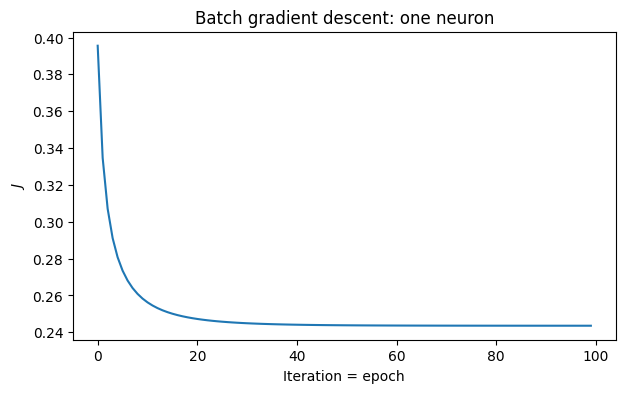

Final J = 0.24356822152507665


In [15]:
alpha = 1.0
n_iterations = 100

W, b = W_start.copy(), b_start.copy()
costs = []

for iteration in range(n_iterations):
    Z, A = forward_neuron(X, W, b)
    dW, db = backward_neuron(X, Y, A)
    W = W - alpha * dW
    b = b - alpha * db
    costs.append(cost_neuron(X, Y, W, b))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(costs)
ax.set_xlabel("Iteration = epoch")
ax.set_ylabel("$J$")
ax.set_title("Batch gradient descent: one neuron")
plt.show()

print("Final J =", costs[-1] if costs else None)

Exercise 1 plots the loss of one example per iteration, while Exercise 2b plots the cost J averaged over all 100 examples. This explains the difference in shape. The SGD curve is noisy because the classes overlap, so some examples are always misclassified and produce spikes of up to about 3.5. These recur at different positions as the data is reshuffled each epoch, and each update follows a single example's gradient, which adds further variation. Batch descent averages these effects out, so J falls smoothly, flattens at about 0.244 after roughly 20 iterations, and shows no spikes. That plateau is the limit of a single neuron on overlapping classes, not a training failure. Per epoch, SGD learns faster, since its loss is already low after the first 100 updates, when batch has made only one. The trade off is that SGD never converges to a single value as its average loss ends at about 0.263, slightly above batch's 0.244, because the weights keep fluctuating around the optimum.

---
## 3. Batch Gradient Descent: One Hidden Neuron and One Output Neuron

The network: $k$ inputs $\to$ 1 ReLU neuron $\to$ 1 sigmoid output neuron, trained on all $n$ examples at once.

| | Shape |
|:--|:--|
| $W^{[1]}$, $b^{[1]}$ | $(k, 1)$, $(1,)$ |
| $Z^{[1]}$, $A^{[1]}$ | $(n, 1)$ |
| $W^{[2]}$, $b^{[2]}$ | $(1, 1)$, $(1,)$ |
| $Z^{[2]}$, $A^{[2]}$ | $(n, 1)$ |

### Example 3: Forward pass and cost

$$Z^{[1]} = XW^{[1]} + b^{[1]}, \quad A^{[1]} = \text{ReLU}(Z^{[1]}), \quad Z^{[2]} = A^{[1]}W^{[2]} + b^{[2]}, \quad A^{[2]} = \sigma(Z^{[2]})$$

These functions work for any number of hidden neurons $h$, with $W^{[1]}$ of shape $(k, h)$ and $W^{[2]}$ of shape $(h, 1)$.

In [16]:
def forward_batch(X, W1, b1, W2, b2):
    """Forward pass for all n examples. Returns Z1, A1, Z2, A2."""
    Z1 = X @ W1 + b1           # (n, h)
    A1 = relu(Z1)
    Z2 = A1 @ W2 + b2          # (n, 1)
    A2 = sigmoid(Z2)
    return Z1, A1, Z2, A2


def cost_batch(X, Y, W1, b1, W2, b2):
    """Cost J: the average loss over all examples."""
    A2 = forward_batch(X, W1, b1, W2, b2)[3]
    return np.mean(bce(A2, Y))

In [17]:
W1_start = np.array([[0.5],
                     [0.3]])
b1_start = np.array([0.1])
W2_start = np.array([[0.4]])
b2_start = np.array([0.0])

Z1, A1, Z2, A2 = forward_batch(X, W1_start, b1_start, W2_start, b2_start)
print("Z1:", Z1.shape, "  A2:", A2.shape)
print("J =", cost_batch(X, Y, W1_start, b1_start, W2_start, b2_start))

Z1: (100, 1)   A2: (100, 1)
J = 0.621570806723156


### Exercise 3a: Backward pass

The same steps as in Example 1, now for all $n$ examples at once:

| Gradient | Formula | Shape |
|:--|:--|:--|
| $\partial J/\partial Z^{[2]}$ | $(A^{[2]} - Y)\,/\,n$ | $(n, 1)$ |
| $\partial J/\partial W^{[2]}$, $\ \partial J/\partial b^{[2]}$ | $A^{[1]\top}\,\dfrac{\partial J}{\partial Z^{[2]}}$, $\ $ sum of the rows of $\dfrac{\partial J}{\partial Z^{[2]}}$ | $(h, 1)$, $(1,)$ |
| $\partial J/\partial A^{[1]}$ | $\dfrac{\partial J}{\partial Z^{[2]}}\,W^{[2]\top}$ | $(n, h)$ |
| $\partial J/\partial Z^{[1]}$ | $\dfrac{\partial J}{\partial A^{[1]}} \odot \text{ReLU}'(Z^{[1]})$ | $(n, h)$ |
| $\partial J/\partial W^{[1]}$, $\ \partial J/\partial b^{[1]}$ | $X^{\top}\,\dfrac{\partial J}{\partial Z^{[1]}}$, $\ $ sum of the rows of $\dfrac{\partial J}{\partial Z^{[1]}}$ | $(k, h)$, $(h,)$ |

Compare with `backward_sgd` in Example 1: the same steps, now done for every neuron and every example at once, divided by $n$.

In [18]:
def backward_batch(X, Y, W2, Z1, A1, A2):
    """Gradients of J for all n examples. Returns dJ/dW1, dJ/db1, dJ/dW2, dJ/db2."""
    n = len(X)
    # output neuron
    dJdZ2 = (A2 - Y) / n
    dJdW2 = A1.T @ dJdZ2
    dJdb2 = dJdZ2.sum(axis=0)
    # back through W2 and the ReLU
    dJdA1 = dJdZ2 @ W2.T
    dJdZ1 = dJdA1 * relu_slope(Z1)
    # hidden neuron
    dJdW1 = X.T @ dJdZ1
    dJdb1 = dJdZ1.sum(axis=0)
    return dJdW1, dJdb1, dJdW2, dJdb2

In [19]:
# Check your answer (should print True)
J_batch = lambda W1, b1, W2, b2: cost_batch(X, Y, W1, b1, W2, b2)
grads = backward_batch(X, Y, W2_start, Z1, A1, A2)
print(gradients_match(grads, numerical_gradients(J_batch, W1_start, b1_start, W2_start, b2_start)))

True


### Exercise 3b: Training

Train for 300 iterations with $\alpha = 1$ and plot the cost $J$ against the iteration (= epoch).

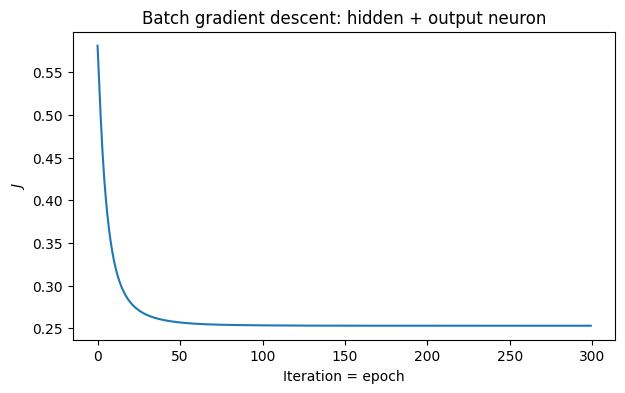

Final J = 0.2530224160143222


In [20]:
alpha = 1.0
n_iterations = 300

W1, b1, W2, b2 = W1_start.copy(), b1_start.copy(), W2_start.copy(), b2_start.copy()
costs = []

for iteration in range(n_iterations):
    Z1, A1, Z2, A2 = forward_batch(X, W1, b1, W2, b2)
    dW1, db1, dW2, db2 = backward_batch(X, Y, W2, Z1, A1, A2)
    W1 = W1 - alpha * dW1
    b1 = b1 - alpha * db1
    W2 = W2 - alpha * dW2
    b2 = b2 - alpha * db2
    costs.append(cost_batch(X, Y, W1, b1, W2, b2))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(costs)
ax.set_xlabel("Iteration = epoch")
ax.set_ylabel("$J$")
ax.set_title("Batch gradient descent: hidden + output neuron")
plt.show()

print("Final J =", costs[-1] if costs else None)